# Example axisymmetric inductor

This notebook builds the model entirely from an in-memory versioned JSON-style dictionary, meshes it with Gmsh, solves the axisymmetric magnetostatic FEM problem, evaluates inductance, and plots the mesh and magnetic flux density.

In [ ]:
%load_ext autoreload
%autoreload 2
from pathlib import Path
import json
import sys
import numpy as np
import matplotlib.pyplot as plt

REPOSITORY_ROOT = Path.cwd().resolve()
if not (REPOSITORY_ROOT / 'fem').is_dir():
    REPOSITORY_ROOT = REPOSITORY_ROOT.parent
if str(REPOSITORY_ROOT) not in sys.path:
    sys.path.insert(0, str(REPOSITORY_ROOT))

from model import load
from fem import (
    COPPER_CONDUCTIVITY_AT_20C_S_PER_M,
    FrequencyDomainResult,
    build_mesh,
    inductance,
    magnetic_flux_density,
    PhysicalField,
    solve_axisymmetric,
    winding_flux_linkage,
)

## Define the model

All dimensions are in metres. The 14 conductor centres reproduce the supplied example geometry.

In [ ]:
FREQUENCY_HZ = 270_000.0
CURRENT_A = 4.5
CORE_RELATIVE_PERMEABILITY = 1500.0
CONDUCTOR_RADIUS_M = 0.0013
MESH_SIZE_M = 0.0005

turn_centres = [
    [0.01175, -0.01245], [0.01485, -0.01245],
    [0.01485, -0.00935], [0.01175, -0.00935],
    [0.01175, -0.00625], [0.01485, -0.00625],
    [0.01485, -0.00315], [0.01175, -0.00315],
    [0.01175, -0.00005], [0.01485, -0.00005],
    [0.01485, 0.00305], [0.01175, 0.00305],
    [0.01175, 0.00615], [0.01485, 0.00615],
]

model_data = {
    'schema': 'pyMagBEM',
    'version': 1,
    'metadata': {'name': 'example inductor', 'units': 'm'},
    'geometry': {
        'coordinate_system': 'axisymmetric_rz',
        'core': {
            'name': 'core', 'material': 'core',
            'corners': [[0, -0.018475], [0.019943733351606967, -0.018475],
                        [0, 0.018475], [0.019943733351606967, 0.018475]]
        },
        'winding_window': {
            'name': 'winding_window', 'material': 'air',
            'corners': [[0.00745, -0.01475], [0.0185, -0.01475],
                        [0.00745, 0.01475], [0.0185, 0.01475]]
        },
        'air_gaps': [{
            'name': 'center_gap', 'material': 'air',
            'center': [0.003725, 0.0], 'size': [0.0, 0.0005]
        }]
    },
    'materials': [
        {'name': 'core', 'relative_permeability': CORE_RELATIVE_PERMEABILITY},
        {'name': 'air', 'relative_permeability': 1.0},
        {'name': 'copper', 'relative_permeability': 1.0,
         'conductivity': COPPER_CONDUCTIVITY_AT_20C_S_PER_M}
    ],
    'conductors': [{
        'name': 'round_copper', 'shape': 'round', 'construction': 'solid',
        'radius': CONDUCTOR_RADIUS_M, 'material': 'copper'
    }],
    'windings': [{
        'name': 'primary', 'conductor': 'round_copper', 'circuit': 'primary',
        'turns': [{'center': centre, 'conductor': 'round_copper',
                   'circuit': 'primary'} for centre in turn_centres]
    }],
    'circuits': [{'name': 'primary', 'turns': len(turn_centres), 'current': CURRENT_A}],
    'excitation': {'type': 'current', 'frequency': FREQUENCY_HZ, 'circuits': {'primary': CURRENT_A}},
    'mesh': {'max_size': MESH_SIZE_M, 'order': 1},
    'solver': {'type': 'axisymmetric_magnetostatic'},
    'output': {'fields': ['A_phi', 'B']}
}
model = load(model_data)
assert len(model.windings[0].turns) == 14
model

FEMModel(schema='pyMagBEM', version=1, metadata=Metadata(name='example inductor', description='', author='', units='m', extra={}), geometry=Geometry(coordinate_system='axisymmetric_rz', core=Region(name='core', material='core', corners=[[0.0, -0.018475], [0.019943733351606967, -0.018475], [0.0, 0.018475], [0.019943733351606967, 0.018475]], center=None, size=None, extra={}), air_gaps=[Region(name='center_gap', material='air', corners=[], center=[0.003725, 0.0], size=[0.0, 0.0005], extra={})], shunts=[], winding_window=Region(name='winding_window', material='air', corners=[[0.00745, -0.01475], [0.0185, -0.01475], [0.00745, 0.01475], [0.0185, 0.01475]], center=None, size=None, extra={}), extra={}), materials=[Material(name='core', relative_permeability=1500.0, permeability_loss_angle_deg=0.0, conductivity=0.0, relative_permittivity=0.0, permittivity_loss_angle_deg=0.0, properties={}), Material(name='air', relative_permeability=1.0, permeability_loss_angle_deg=0.0, conductivity=0.0, relati

In [3]:
mesh = build_mesh(model, max_size=MESH_SIZE_M)
conductor_name = next(iter(mesh.conductor_regions))
conductor_area = np.pi * CONDUCTOR_RADIUS_M ** 2
current_density = {'winding': CURRENT_A / conductor_area}
a_phi = solve_axisymmetric(
    mesh,
    relative_permeability={'core': CORE_RELATIVE_PERMEABILITY},
    current_density=current_density,
)
result = FrequencyDomainResult.from_solution(
    model, mesh, a_phi, {name: np.full(len(mesh.triangles), current_density["winding"]) for name in mesh.conductor_regions},
    frequency_hz=FREQUENCY_HZ,
)

flux_density = magnetic_flux_density(mesh, a_phi)
flux_density_magnitude = np.linalg.norm(flux_density, axis=1)
energy_inductance_h = inductance(mesh, a_phi, CURRENT_A, current_density)
flux_linkage_wb = winding_flux_linkage(mesh, a_phi, CURRENT_A)
linkage_inductance_h = flux_linkage_wb / CURRENT_A

print(f'Frequency: {FREQUENCY_HZ:,.0f} Hz')
print(f'Current: {CURRENT_A:.3f} A')
print(f'Mesh: {len(mesh.points)} nodes, {len(mesh.triangles)} triangles')
print(f'Winding current density: {current_density["winding"]:,.3e} A/mÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â²')
print(f'Energy inductance: {energy_inductance_h * 1e6:.4f} ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚ÂµH')
print(f'Flux-linkage inductance: {linkage_inductance_h * 1e6:.4f} ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚ÂµH')
print(f'Maximum |B|: {flux_density_magnitude.max():.4f} T')

Frequency: 270,000 Hz
Current: 4.500 A
Mesh: 5895 nodes, 11559 triangles
Winding current density: 8.476e+05 A/mÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â²
Energy inductance: 89.9374 ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚ÂµH
Flux-linkage inductance: 90.6517 ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚ÂµH
Maximum |B|: 0.4853 T


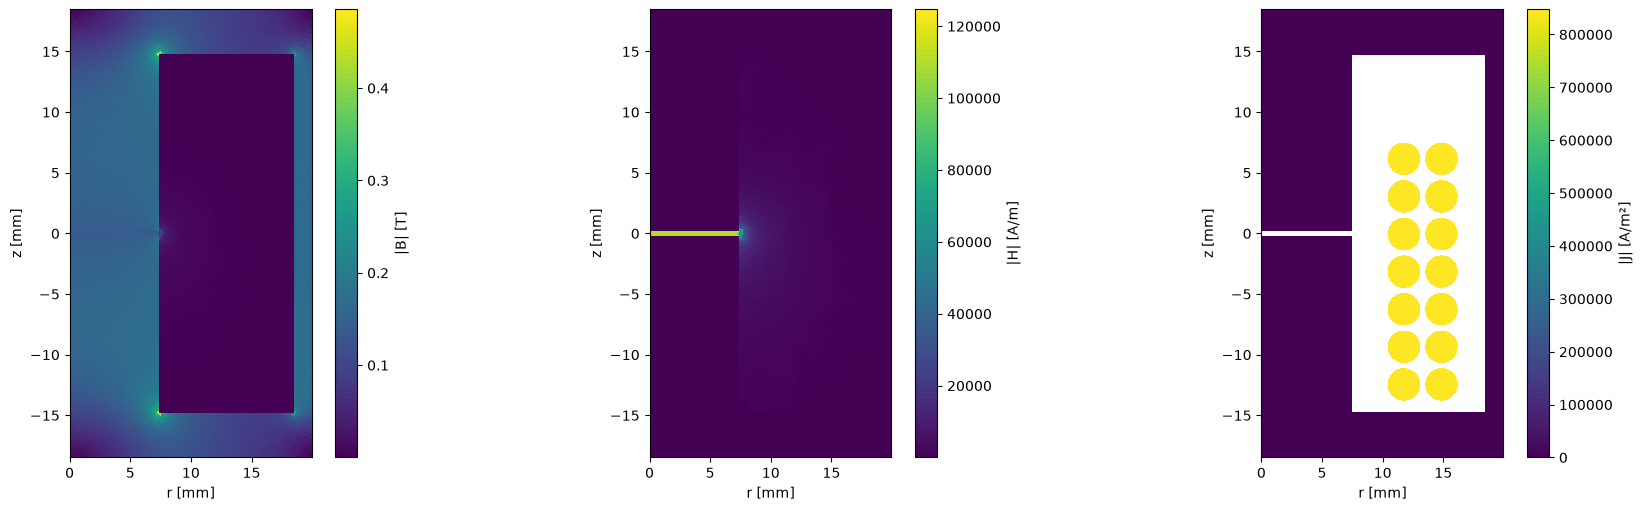

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
result.plot_physical_field(PhysicalField.B, ax=axes[0])
result.plot_physical_field(PhysicalField.H, ax=axes[1])
result.plot_physical_field(PhysicalField.J, ax=axes[2])
plt.show()